# Undertow DeepSea & False Beacon Frozen Lake
### Why more exploration can buy the wrong evidence

**Read the maps first.** A route can reach a dock, collect observations, and still fail to reveal that another route is better. These benchmarks separate **reward**, **coverage**, and **decision-relevant evidence**.

This walkthrough contains kernel-generated route illustrations, exact finite-model checks, and verified cached learning curves. Its default execution launches **no training**, downloads nothing, and needs no raw study folder.

**Setup must happen before launching the kernel.** From the repository root, in a terminal:

```bash
python3 -m venv .venv
source .venv/bin/activate
python -m pip install -e '.[notebook]'
python -m ipykernel install --sys-prefix --name ceac-undertow --display-name "Python (CEAC)"
python -m jupyter lab notebooks/Undertow_FalseBeacon.ipynb
```

Choose **Python (CEAC)**. In VS Code, select this repository's `.venv/bin/python`. Python 3.10 or newer is required; `ipykernel` is included in the notebook extra. Do not use the archived `legacy/inforatio` installer.

The saved outputs are also readable directly on GitHub.

In [1]:
from pathlib import Path
import sys, importlib.util

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "pyproject.toml").is_file() and (p / "ceac/model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the cloned CEAC repository.")
if sys.version_info < (3, 10):
    raise RuntimeError("Select the CEAC kernel with Python 3.10 or newer.")
missing = [name for name in ("numpy", "scipy", "matplotlib", "IPython", "ceac", "ceac_walkthrough")
           if importlib.util.find_spec(name) is None]
if missing:
    raise RuntimeError(f"Missing {missing}. In this kernel's environment run: "
                       f"{sys.executable} -m pip install -e '{ROOT}[notebook]'")
import numpy as np
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from ceac.model import FiniteModel
from ceac_walkthrough.evidence import verified_bundle
from ceac_walkthrough.visuals import (draw_undertow, draw_false_beacon, draw_signal_laws,
                                     draw_policy_facts, draw_learning)

bundle, provenance = verified_bundle(ROOT / "notebooks")
print(f"Python {sys.version.split()[0]} | verified {provenance['source_runs']} unique source runs")
print(f"Portable export: {provenance['curve_runs']} per-seed learning traces; no raw-cache dependency.")

Python 3.11.13 | verified 384 unique source runs
Portable export: 108 per-seed learning traces; no raw-cache dependency.


## 1. Undertow: the horizon is a navigation budget

**Blue reaches the goal. Magenta generates observations while losing the ability to reach it.** Every rightward move spends one depth unit and gains one column. The nuisance action spends depth without gaining a column. Its random symbols have the same law in both candidate modes.

The gate offers a different choice: a small-cost probe reveals a mode-sensitive bit. A challenge follows the ordinary route geometry but has a mode-dependent payoff. The map below is generated by actual `reset`/`step` calls; it is an illustrative trajectory, not a trained-policy success statistic.

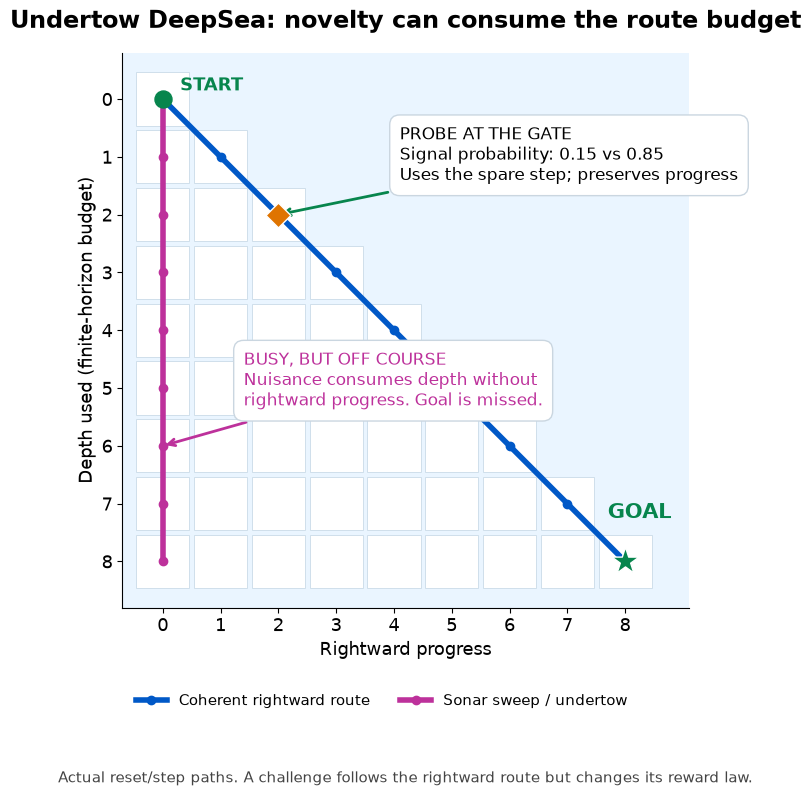

In [2]:
fig = draw_undertow()
plt.show()

## 2. False Beacon: a successful route can leave the decision unresolved

**The inner route has the same trajectory law in both modes; the outer route becomes better in mode 1.** Repeating the inner route therefore cannot detect this opportunity.

The noisy reeds are a false beacon: they offer more observable variety without revealing the mode. The deep survey supplies useful evidence. The shallow survey is also uninformative about the mode. Geometry and paths below come from the environment implementation. Random terminal outcomes mean reaching a dock and obtaining a reward are distinct events.

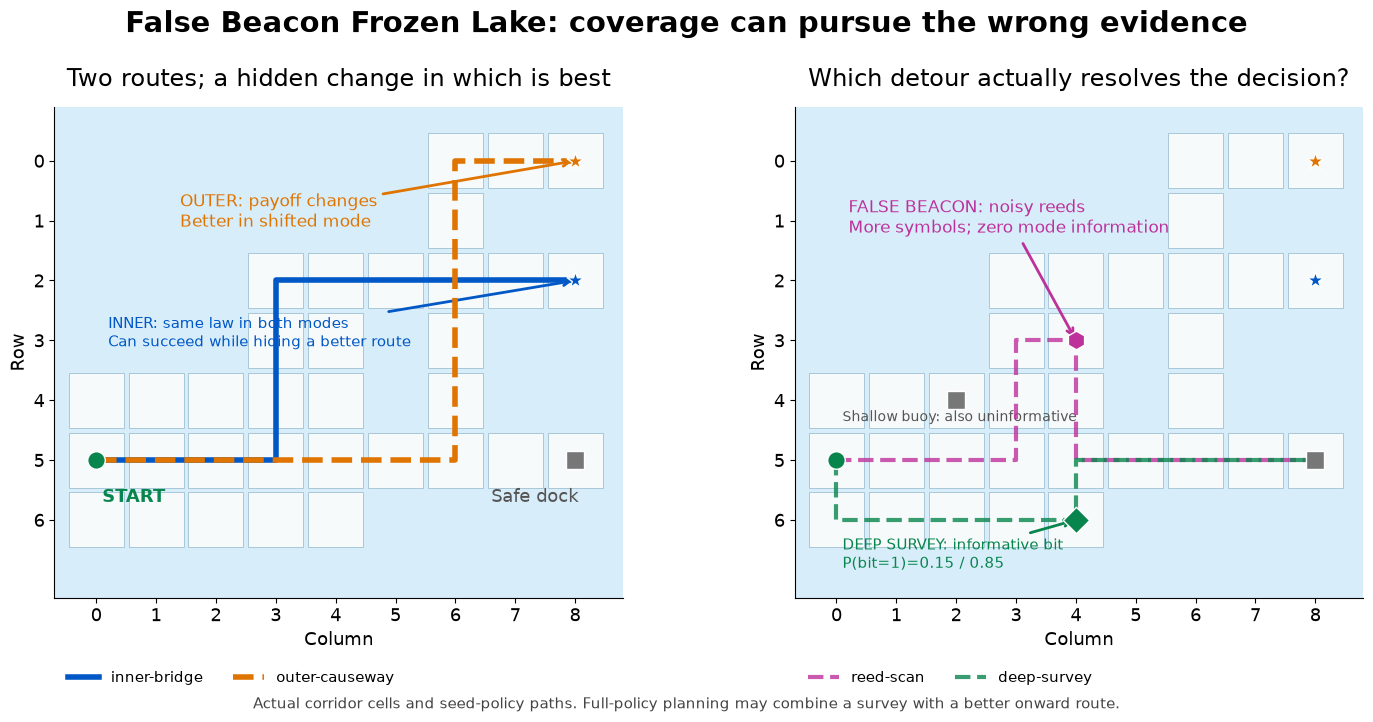

In [3]:
fig = draw_false_beacon()
plt.show()

## 3. What makes an observation useful?

The relevant quantity is a likelihood ratio against a **policy-changing** alternative, not the number of distinct symbols. If both modes emit a symbol with probability $1/M$, its log likelihood ratio is zero even though its entropy is $\log M$.

The two-outcome probe is much simpler, but separates Bernoulli(0.15) from Bernoulli(0.85):

$$D_{\mathrm{KL}} = 0.7\log(17/3) \simeq 1.214\ \text{nats}.$$

**A richer observation alphabet can be less useful for the decision.** These charts show declared observation laws, not sampled training histograms.

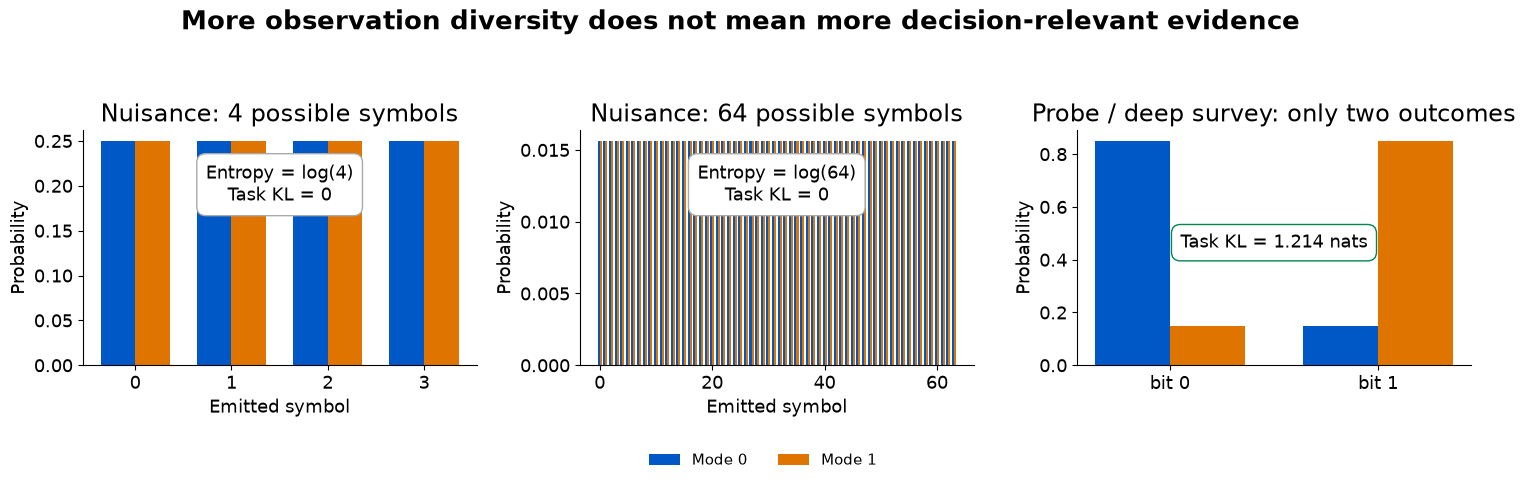

In [4]:
fig = draw_signal_laws()
plt.show()

## 4. Check the pathology against the actual finite models

We now compile both candidate laws from each environment's `step()` behavior at **weak signal, M=4**, and evaluate the seed policies exactly. This is diagnostic planning, not self-play training.

The assertions require: (i) the old route is observationally identical across modes, (ii) it becomes suboptimal in mode 1, (iii) the nuisance policy has zero task KL, and (iv) the probe/survey is informative. The frozen-lake survey shown is the declared seed route; full-policy separation can synthesize a better onward continuation.

Both environments pass the confounding, nuisance and informative-probe checks.


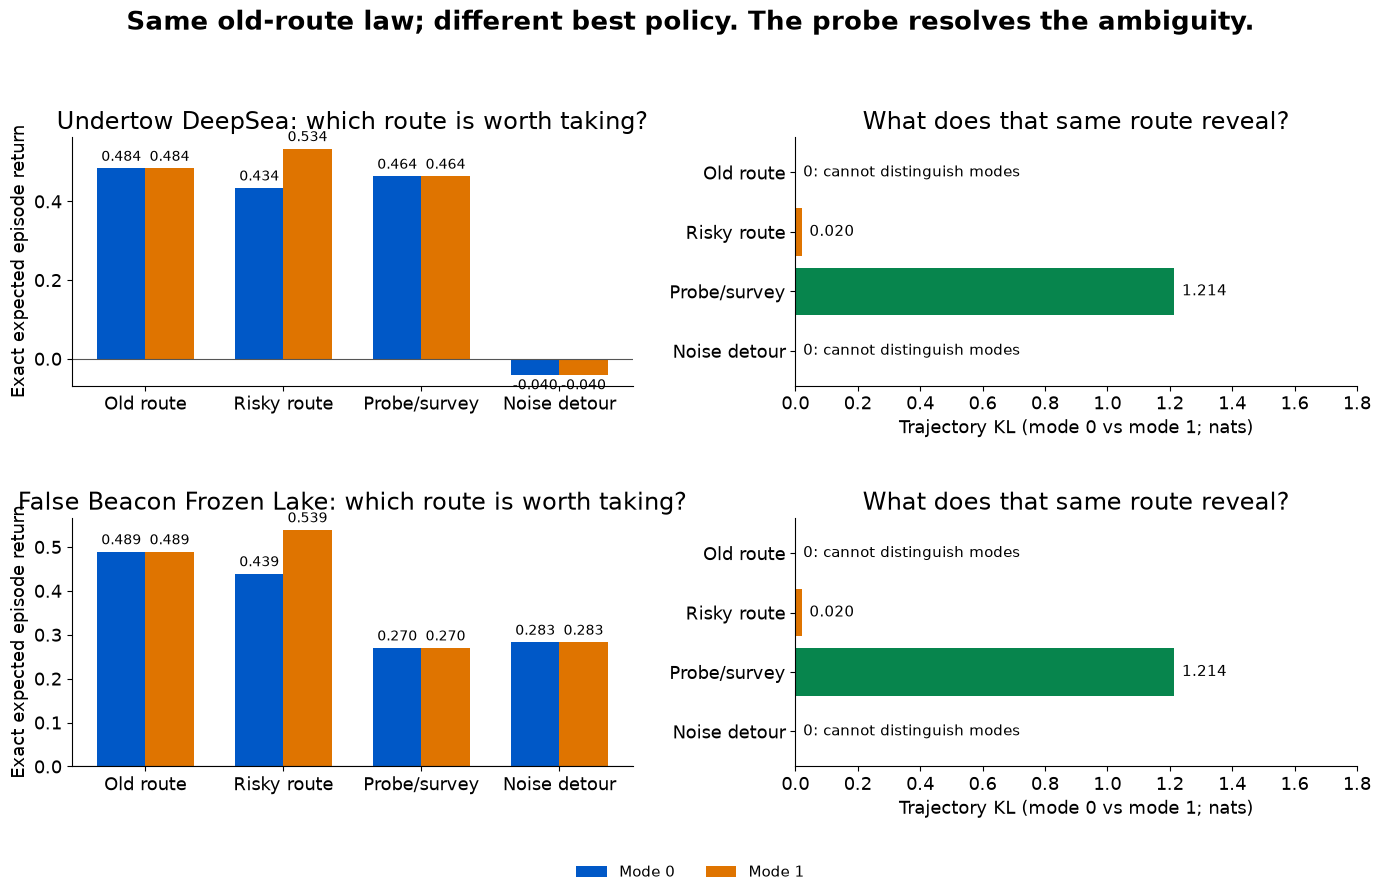

In [5]:
models = {kind: FiniteModel(kind, benchmark="weak_signal_m4")
          for kind in ("deepsea", "frozenlake")}
for kind, model in models.items():
    policies = {p.label: p for p in model.seed_policies()}
    old, noise, probe = (("exploit", "sonar-sweep", "probe") if kind == "deepsea"
                         else ("inner-bridge", "reed-scan", "deep-survey"))
    values, information = model.evaluate(policies[old])
    np.testing.assert_allclose(information, 0, atol=1e-12)
    np.testing.assert_allclose(values[0], values[1], atol=1e-12)
    assert model.optimal_returns[1] - values[1] > 0.049
    np.testing.assert_allclose(model.evaluate(policies[noise])[1], 0, atol=1e-12)
    assert model.evaluate(policies[probe])[1][0, 1] > 1.2
print("Both environments pass the confounding, nuisance and informative-probe checks.")
fig = draw_policy_facts(models)
plt.show()

## 5. What the completed experiments actually show

These curves are saved **weak-signal M=64, mode-0** experiments: three seeds, 512 episodes, seven methods. Expected policy return is computed by the evaluator only. Return smoothing is causal and applied within each seed. Shading is **mean ±1 sample SD**, not a confidence interval.

**CEAC resolves the decision while broad coverage and the OIR/IDAC adaptation keep paying for distraction. Full-support IDS is also strong.** We retain that successful control. The offline oracle receives the true mode; CEAC does not. Episode budgets match, but planning and primitive-step costs are not claimed equal.

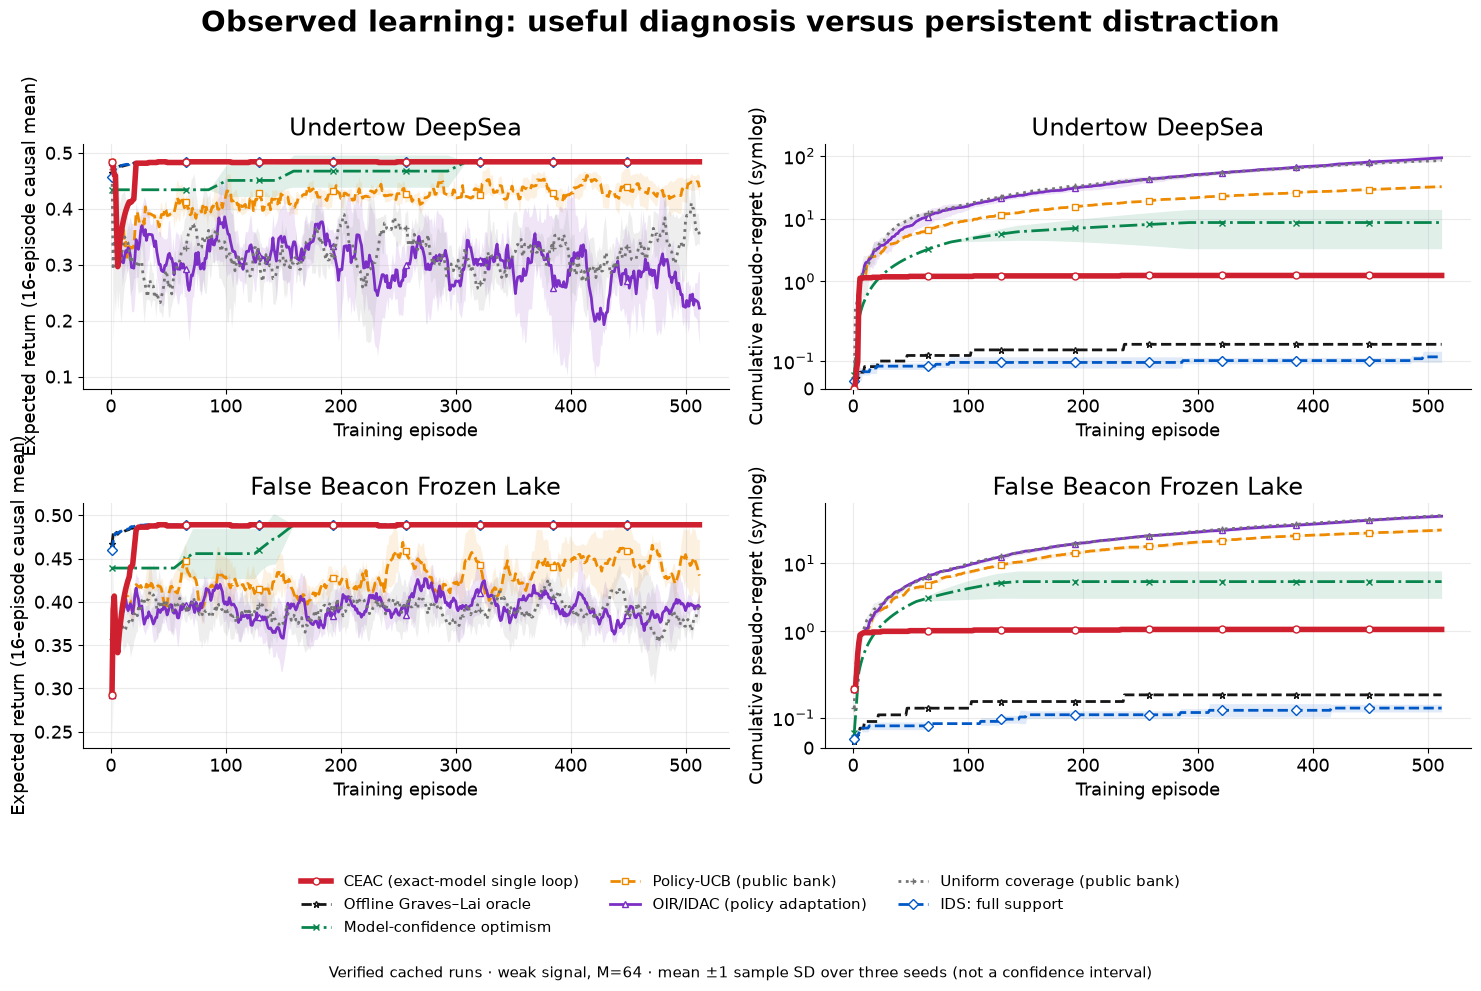

In [6]:
fig = draw_learning(bundle)
plt.show()

## 6. Increase nuisance diversity without changing the task

The following aggregate keeps route probability separation at 0.05 and increases the nuisance alphabet from $M=4$ to 16 to 64. Geometry, policy-bank size and useful diagnostic signal remain fixed. The middle column subtracts the $M=4$ baseline **within each paired seed** before estimating variation.

**OIR/IDAC deteriorates clearly in DeepSea and modestly in Frozen Lake; CEAC stays stable.** Full-support IDS stays stable too. Confidence, policy-UCB and uniform coverage have mostly unchanged costs. This does not show every alternative deteriorating, and $M$ is not physical current strength.

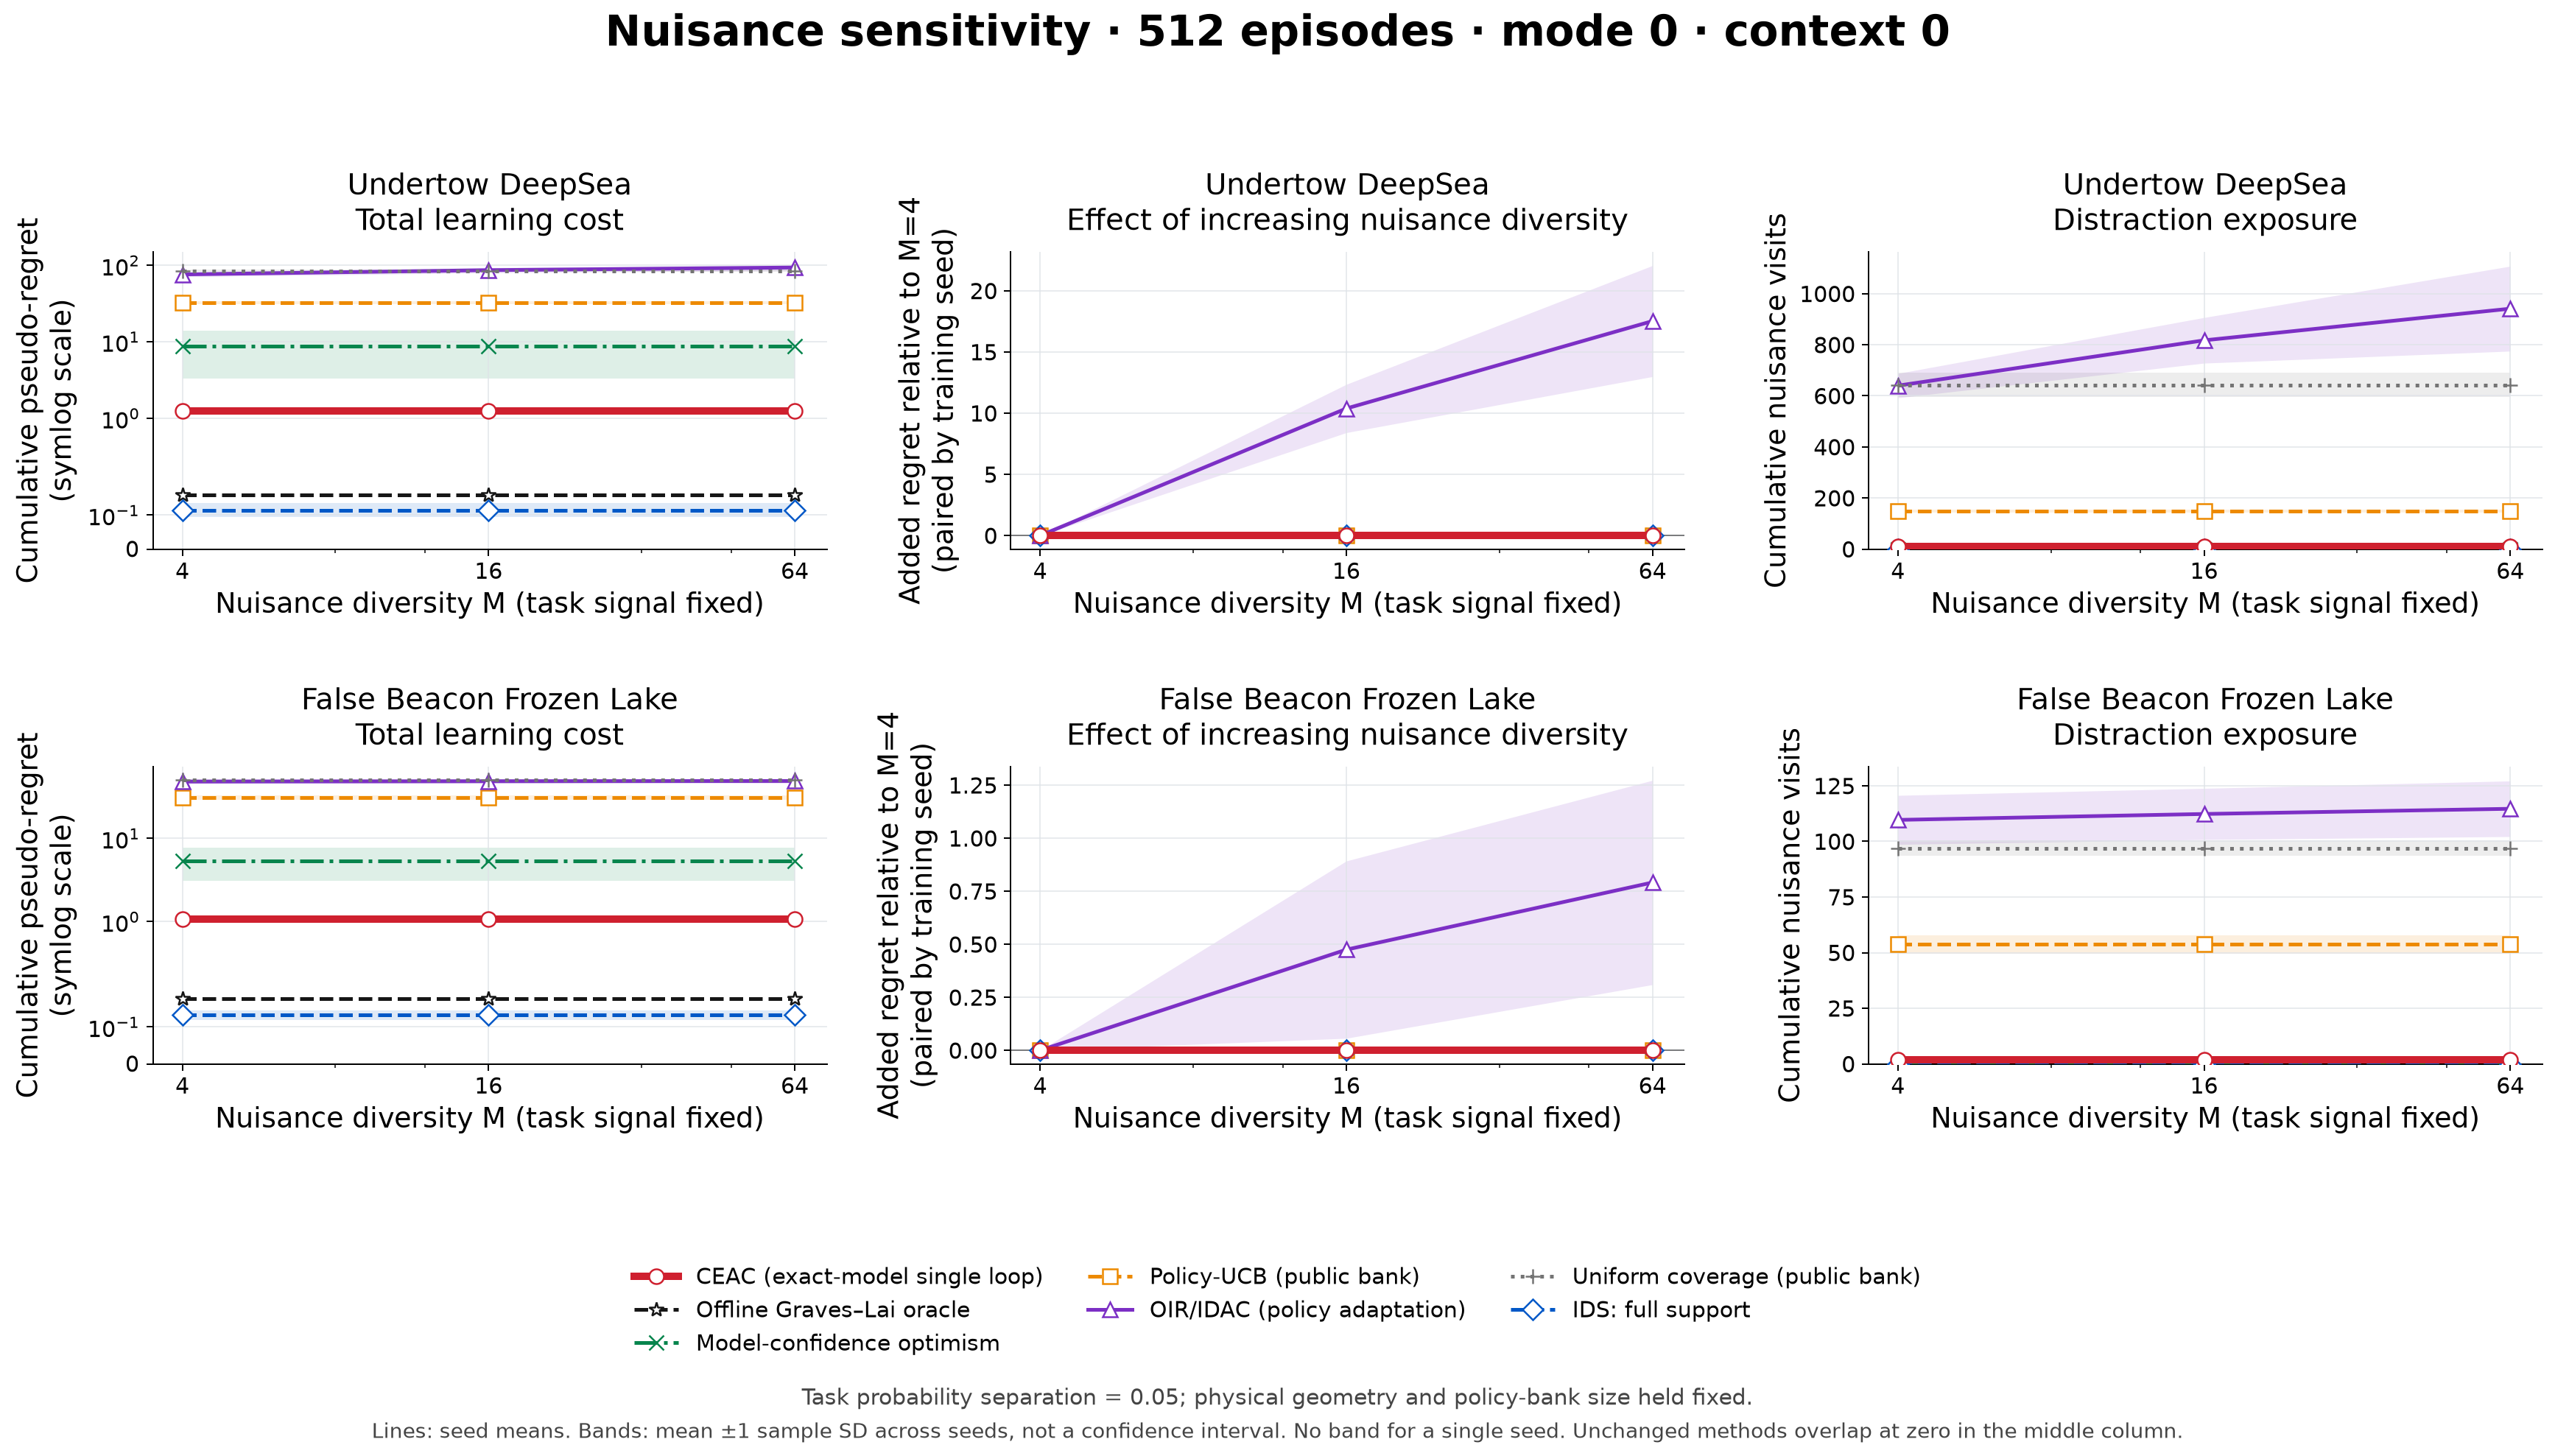

In [7]:
display(Image(filename=str(ROOT / "notebooks/assets/aggregate_nuisance_context0_mode0.png")))

## 7. Breaking Bayesian support is a separate treatment

Here the environment is in mode 1. IDS uses the same candidate laws but assigns mode 1 prior mass 0.5, 0.001, or exactly zero. With zero prior mass,

$$p_t(1)=\frac{p_0(1)L_t(1)}{p_0(0)L_t(0)+p_0(1)L_t(1)}=0.$$

The old route is subjectively optimal and supplies no evidence against the supported model. Its true gap is 0.05, so the excluded-support arm incurs exactly $512\times0.05=25.6$ pseudo-regret. A rare **positive** prior can recover and must not be conflated with exclusion.

**This is an explicit information-assumption difference.** CEAC still has both candidates; these curves do not prove that it can discover an undeclared model. All runs here have a fixed mode—there is no hidden within-run change point.

Checked exact zero-support prediction for all 6 shifted-mode seed runs.


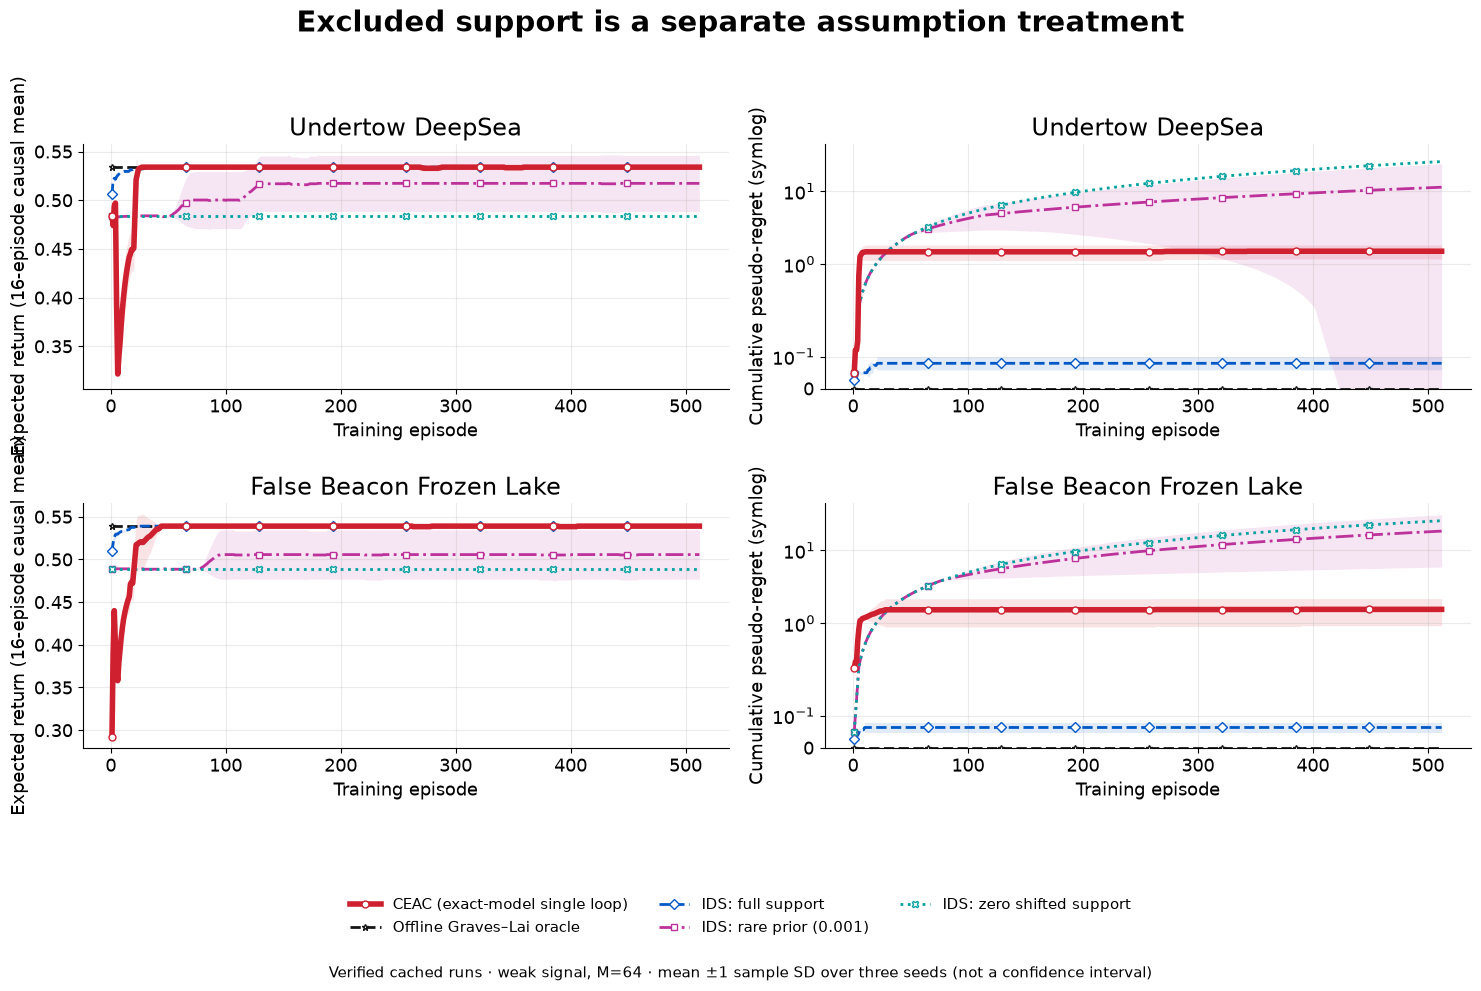

In [8]:
excluded = [r for r in bundle["curves"] if r["result"]["method"] == "ids_zero"
            and r["result"]["true_mode"] == 1]
for run in excluded:
    posterior = [m["diagnostics"]["posterior"][1] for m in run["metrics"]]
    np.testing.assert_array_equal(posterior, 0)
    np.testing.assert_allclose([m["cumulative_pseudo_regret"] for m in run["metrics"]],
                               .05 * np.arange(1, 513), atol=1e-8, rtol=0)
print(f"Checked exact zero-support prediction for all {len(excluded)} shifted-mode seed runs.")
fig = draw_learning(bundle, prior=True)
plt.show()

## 8. What “CEAC” and “certified deployment” mean here

This is the maintained **single episode-loop, exact-model specialization** of CEAC. Its behavior scheduler serves statistical requests and design debts first. On free episodes, it uses a reward-only policy if

$$\max_{m\in\mathcal C_t}\big[J_m^\star-J_m(\widehat\pi_t)\big]\le10^{-10}.$$

Here $\mathcal C_t$ is inferred from trajectory likelihoods. The guarantee applies on the model-confidence event within the declared family. It does not certify an arbitrary misspecified environment.

| | CEAC in these runs | Offline Graves–Lai oracle |
|---|---|---|
| Realized mode | Unknown; learned from trajectories | Supplied from the outset |
| Design | Refreshed using accumulated evidence | Normalized allocation computed once |
| Free-episode execution | Confidence-set-certified reward-only response | True-model optimal policy |
| Planning | Exact candidate-model evaluation and separation | Same access plus true mode |

The oracle's curve includes its scheduled experiments; it is not a finite-time lower bound. Exact separation and deployment planning are explicit implementation choices documented in the ledgers. **The curves do not isolate a causal benefit from the learned TD evidence critic.**

In [9]:
history = [r for r in bundle["history_audits"] if r["method"] == "ceac"]
assert len(history) == 48
zero = sum(r["actor_updates"] == 0 for r in history)
admitted = sum(r["actor_admissions"] for r in history)
print(f"CEAC audit: {zero}/{len(history)} runs made zero actor/critic updates.")
print(f"Learned actor proposals admitted: {admitted}.")
print("Cumulative likelihood estimates, confidence sets and policy credits were reconstructed from saved trajectories.")
print("Mechanism attribution requires a learned-estimator experiment with matched ablations.")

CEAC audit: 34/48 runs made zero actor/critic updates.
Learned actor proposals admitted: 0.
Cumulative likelihood estimates, confidence sets and policy credits were reconstructed from saved trajectories.
Mechanism attribution requires a learned-estimator experiment with matched ablations.


## 9. Reproduce or extend, with one runner

The default notebook is complete. The cell below prints a small integration-study command; it does not launch it. Run that command in a terminal from the repository root if desired. Choose a fresh output name for each scientific study. A short integration check does not establish convergence.

```bash
python -m ceac.report --input runs/notebook_smoke
```

For the full cached-slate specification and mathematical deviations, see [the maintained guide](../ceac/README.md), [the benchmark ledger](../audits/ceac_undertow_design_20261110.md), and [the v90 implementation ledger](../audits/ceac_v90_corrections_20261110.md). The manuscripts and raw historical caches are separate reference artifacts; this notebook needs neither.

For headless notebook verification: `python scripts/verify_notebook.py`. To rebuild the portable evidence from the original raw caches: `python scripts/export_walkthrough.py`.

In [10]:
import shlex
command = ["python", "-m", "ceac.run", "--output", "runs/notebook_smoke",
           "--benchmarks", "weak_signal_m4", "--environments", "deepsea", "frozenlake",
           "--methods", "ceac", "oracle", "confidence", "policy_ucb", "oir_idac", "coverage", "ids",
           "--modes", "0", "1", "--seeds", "0", "--episodes", "32", "--workers", "1"]
print(shlex.join(command))
print("Notebook complete. No training was launched.")

python -m ceac.run --output runs/notebook_smoke --benchmarks weak_signal_m4 --environments deepsea frozenlake --methods ceac oracle confidence policy_ucb oir_idac coverage ids --modes 0 1 --seeds 0 --episodes 32 --workers 1
Notebook complete. No training was launched.
